# 03 — Exploratory data analysis (EDA)

**Goal.** Describe the data before modelling: size, class imbalance, missing values, outliers,
correlations, and the first differences between hospital A and hospital B.

**Input.** Files saved by `02_data_preparation.ipynb` (run it first):
- `data/processed/hourly.pkl` — one row per patient-hour, both hospitals
- `data/processed/patients_splits.csv` — one row per patient, with its split (train / calib / test)

**Rule against leakage.** Anything that could guide a modelling choice (correlations) is computed
on **hospital A training patients only**. Purely descriptive numbers use all patients.

Figures are saved in `report/figures/` for the report.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

SEED = 42
PROCESSED = Path("../data/processed")
FIG = Path("../report/figures")
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 3)

data = pd.read_pickle(PROCESSED / "hourly.pkl")
patients = pd.read_csv(PROCESSED / "patients_splits.csv")
data.shape, patients.shape

((1552210, 43), (40336, 5))

In [2]:
# Variable groups
VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"]
NOT_INPUTS = ["SepsisLabel", "patient_id", "hospital"]
ALWAYS_PRESENT = ["Age", "Gender", "ICULOS"]      # never missing (checked in notebook 02)

# Variables that can be missing: vital signs, lab values, Unit1, Unit2, HospAdmTime
VARS = [c for c in data.columns if c not in NOT_INPUTS + ALWAYS_PRESENT]
len(VARS)

37

## 1. Dataset size and length of stay

In [3]:
# One row per hospital: number of patients, number of hours, length of stay (LOS)
# Median and quartiles instead of the mean: a few very long stays would pull the mean up.
summary = patients.groupby("hospital").agg(
    n_patients=("patient_id", "size"),
    n_hours=("n_hours", "sum"),
    los_median=("n_hours", "median"),
    los_q1=("n_hours", lambda x: x.quantile(0.25)),
    los_q3=("n_hours", lambda x: x.quantile(0.75)),
    los_max=("n_hours", "max"),
)
summary

,n_patients,n_hours,los_median,los_q1,los_q3,los_max
hospital,,,,,,
A,20336,790215,39.0,25.0,47.0,336
B,20000,761995,38.0,23.0,47.0,336


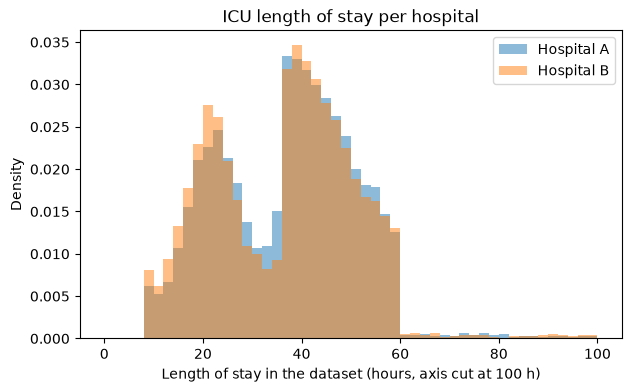

In [4]:
# Distribution of the length of stay (density = both hospitals on the same scale)
fig, ax = plt.subplots(figsize=(7, 4))
for h, p in patients.groupby("hospital"):
    ax.hist(p["n_hours"], bins=50, range=(0, 100), alpha=0.5, density=True, label=f"Hospital {h}")
ax.set_xlabel("Length of stay in the dataset (hours, axis cut at 100 h)")
ax.set_ylabel("Density")
ax.set_title("ICU length of stay per hospital")
ax.legend()
fig.savefig(FIG / "eda_length_of_stay.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations.**
- Hospital A: 20 336 patients, 790 215 patient-hours. Hospital B: 20 000 patients, 761 995 patient-hours.
- The length of stay is almost the same in both hospitals (median 39 h in A, 38 h in B; half of the
  stays between ~24 h and 47 h): it is **not** what makes A and B different.
- The shape of the distribution is not that of natural ICU stays: no stay is shorter than 8 h,
  there are two peaks (around 20 h and 40 h), a sharp drop at 60 h, and the maximum is exactly
  336 h (14 days) in both hospitals. The records were most likely selected and cut by the
  challenge organisers (to check in the PhysioNet paper) — a limitation to mention in the report.

## 2. Class imbalance

In [5]:
# Imbalance at two levels:
# - patients: share of patients who develop sepsis at some point
# - hours: share of rows labelled 1 (this is what the model predicts, hour by hour)
imbalance = pd.DataFrame({
    "share_septic_patients": patients.groupby("hospital")["ever_sepsis"].mean(),
    "share_positive_hours": data.groupby("hospital")["SepsisLabel"].mean(),
})
# A model that always answers "no sepsis" is right on every negative hour
imbalance["accuracy_always_0"] = 1 - imbalance["share_positive_hours"]
# A random model has an AUPRC equal to the share of positive hours
imbalance["auprc_random_model"] = imbalance["share_positive_hours"]
imbalance

,share_septic_patients,share_positive_hours,accuracy_always_0,auprc_random_model
hospital,,,,
A,0.088,0.022,0.978,0.022
B,0.057,0.014,0.986,0.014


**Observations.**
- 8.8 % of patients in A develop sepsis vs 5.7 % in B; 2.17 % of hours are positive in A vs 1.41 % in B.
  Sepsis is about 1.5 times more frequent in A: this is a **label-prevalence shift**.
- A model that always answers "no sepsis" reaches ~98 % accuracy while detecting nobody,
  so accuracy is useless here. Our main metric is the **AUPRC**; a random model gets ~0.02 in A
  and ~0.014 in B, which is the floor the baseline must clearly beat.

## 3. Missing values

We use the **raw** data (not the filled values of notebook 02) to see when a variable was
really measured. A lab test is ordered when a doctor suspects a problem, so missingness carries
clinical information, and it may differ between hospitals (missingness shift).

In [6]:
# Share of patient-hours where each variable is measured, per hospital
# (notna() is True/False; the mean of True/False is a proportion)
measured = data[VARS].notna().groupby(data["hospital"]).mean().T
measured.sort_values("A", ascending=False)

hospital,A,B
HospAdmTime,1.000,1.000
HR,0.923,0.879
Resp,0.902,0.789
MAP,0.898,0.852
O2Sat,0.880,0.859
SBP,0.848,0.861
DBP,0.519,0.861
Unit2,0.511,0.704
Unit1,0.511,0.704
Temp,0.338,0.339


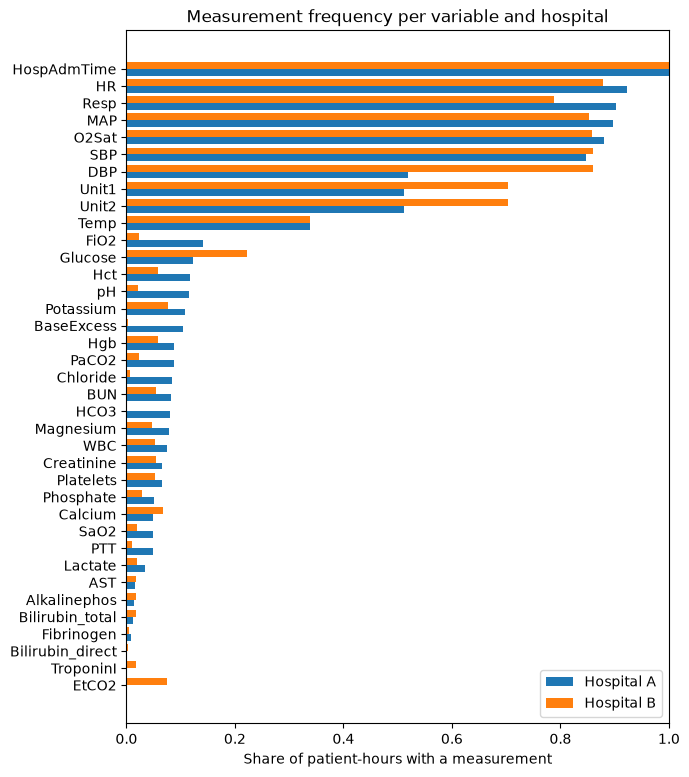

In [7]:
# Figure: two bars per variable (A and B), sorted by measurement frequency in A
m = measured.sort_values("A")
y = np.arange(len(m))
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(y - 0.2, m["A"], height=0.4, label="Hospital A")
ax.barh(y + 0.2, m["B"], height=0.4, label="Hospital B")
ax.set_yticks(y, m.index)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of patient-hours with a measurement")
ax.set_title("Measurement frequency per variable and hospital")
ax.legend(loc="lower right")
fig.savefig(FIG / "eda_missingness.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Largest differences between hospitals (positive = measured more often in A)
diff = (measured["A"] - measured["B"]).sort_values(key=abs, ascending=False)
diff.head(10)

DBP          -0.342
Unit1        -0.192
Unit2        -0.192
FiO2          0.119
Resp          0.114
BaseExcess    0.102
Glucose      -0.099
pH            0.092
HCO3          0.079
Chloride      0.077
dtype: float64

**Observations.**
- Vital signs are measured in most hours (HR: 92 % of hours in A, 88 % in B; Resp, MAP, O2Sat and
  SBP: 79–90 %), temperature only about one hour in three (34 %), and laboratory values rarely
  (usually under 15 % of hours, at most 22 % for Glucose in B; Lactate 3.4 % in A and 1.9 % in B; Bilirubin_direct, TroponinI and
  Fibrinogen under 2 %).
- The two hospitals do **not** measure the same things:
  - blood gases are far more frequent in A: BaseExcess 10.4 % vs 0.2 % of hours, HCO3 8.1 % vs 0.2 %,
    pH 11.5 % vs 2.2 %, PaCO2 8.8 % vs 2.2 %, FiO2 14.2 % vs 2.3 %, Chloride 8.3 % vs 0.6 %;
  - other variables are more frequent in B: DBP (86 % vs 52 %, the largest gap), Glucose (22 % vs 12 %),
    TroponinI (1.8 % vs 0.1 %);
  - EtCO2 is **never** measured in A (7.6 % of hours in B): a model trained on A cannot use it;
  - the ICU type (Unit1/Unit2) is known for 51 % of hours in A and 70 % in B.
- Consequence: missingness carries clinical information, which is why notebook 02 adds
  "never measured" indicators. But these indicators also partly encode the hospital: a model
  trained on A learns from blood-gas values that are almost always missing in B. This
  **missingness shift** is a likely cause of performance loss from A to B (secondary question 2
  of Deliverable 1).

## 4. Outliers (vital signs)

For each vital sign: number of measurements, mean, min, max and percentiles
(the 0.1 % percentile is the value below which the lowest 0.1 % of measurements lie).
We look mostly at `min` and `max`:
- a value that is **impossible** for a human (e.g. a temperature of 20 °C, a saturation above 100 %)
  is a recording error;
- a value that is **extreme but possible** in a very sick patient is real information.

In [9]:
vitals_table = data[VITALS].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T
vitals_table.round(1)

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
HR,1.399e+06,84.6,17.3,20.0,40.0,50.0,83.5,130.0,150.0,280.0
O2Sat,1.349e+06,97.2,2.9,20.0,73.0,89.0,98.0,100.0,100.0,100.0
Temp,5.252e+05,37.0,0.8,20.9,33.0,35.1,37.0,38.8,39.7,50.0
SBP,1.326e+06,123.8,23.2,20.0,64.0,80.0,121.0,186.0,213.0,300.0
MAP,1.359e+06,82.4,16.3,20.0,40.0,52.0,80.0,128.0,157.5,300.0
DBP,1.066e+06,63.8,14.0,20.0,29.0,38.0,62.0,103.0,130.0,300.0
Resp,1.314e+06,18.7,5.1,1.0,3.0,9.0,18.0,34.0,43.0,100.0
EtCO2,5.764e+04,33.0,8.0,10.0,10.0,13.0,33.0,52.0,83.4,100.0


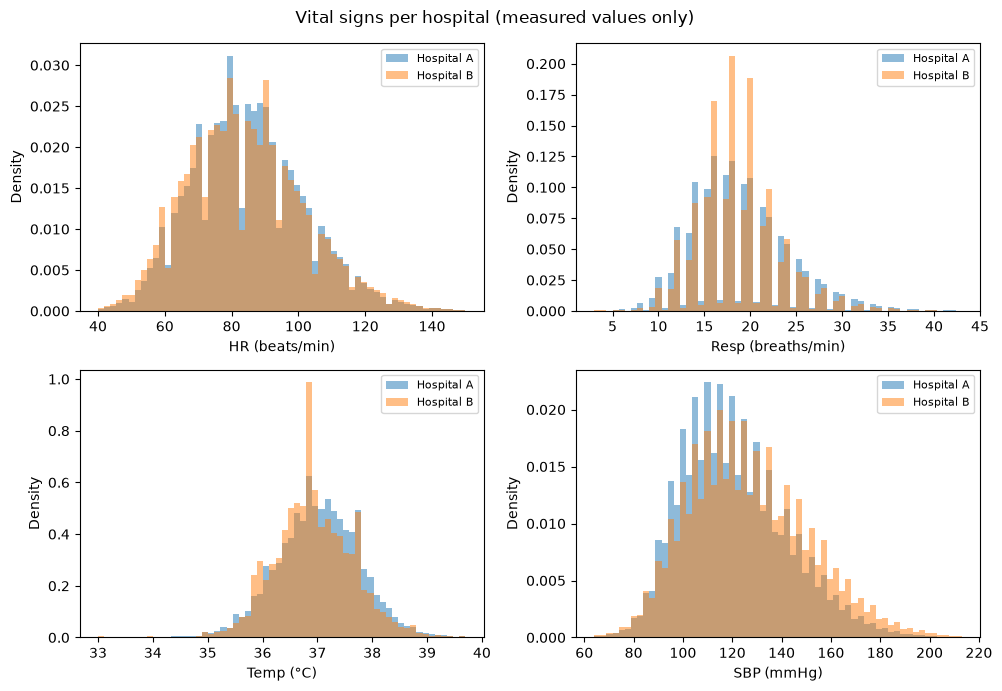

In [10]:
# Distributions of four vital signs per hospital.
# The x axis covers the central 99.8 % of values (0.1 % to 99.9 % percentiles) so the bulk is readable.
units = {"HR": "beats/min", "Resp": "breaths/min", "Temp": "°C", "SBP": "mmHg"}
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (v, unit) in zip(axes.ravel(), units.items()):
    low, high = data[v].quantile([0.001, 0.999])
    for h, d in data.groupby("hospital"):
        ax.hist(d[v].dropna(), bins=60, range=(low, high), alpha=0.5, density=True, label=f"Hospital {h}")
    ax.set_xlabel(f"{v} ({unit})")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
fig.suptitle("Vital signs per hospital (measured values only)")
fig.tight_layout()
fig.savefig(FIG / "eda_vital_signs.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations.**
- Most values are plausible: the central 99.8 % of measurements lie in 40–150 beats/min for HR,
  33.0–39.7 °C for Temp, 64–213 mmHg for SBP, 3–43 breaths/min for Resp.
- But the extremes include values that are physically impossible: Temp of 20.9 °C and 50 °C,
  Resp of 100 breaths/min, MAP and DBP of 300 mmHg.
- Many minima and maxima are round limits (20 for HR, O2Sat, SBP, MAP and DBP; 300 for SBP, MAP
  and DBP; 100 for Resp and EtCO2): the values were probably already capped at these limits
  when the data was collected or curated.
- The histograms have a "comb" shape (HR, Resp, Temp): values are mostly recorded as round
  numbers, so some bins contain more possible values than others. This is a recording artefact,
  not a clinical pattern.
- SBP is slightly higher in B than in A (also visible in section 6).

**Decision on outliers** *(proposed — to confirm in the team)*.
1. We **keep all raw values** in the processed data: we cannot always tell a recording error from
   a very sick patient, and the challenge organisers kept them.
2. For the **logistic regression baseline** (notebook 04), which is sensitive to extreme values, each
   continuous variable is clipped to its 0.5 % and 99.5 % percentiles. The limits are **learned on
   the training patients only, inside the Pipeline**, so no test value influences them. 0/1 indicator
   columns are not clipped.
3. Tree-based models (Deliverable 3) only use the order of the values and do not need clipping.

## 5. Correlations between variables (hospital A, training patients only)

Spearman correlation (based on ranks: it catches any monotonic relation, not only linear ones,
and it is not sensitive to outliers). Computed on raw measurements, on a random sample of
200 000 hours of **A-train** patients only, so the test patients never influence a modelling choice.
A pair is only used when both variables were measured at the same hour (at least 500 such hours).

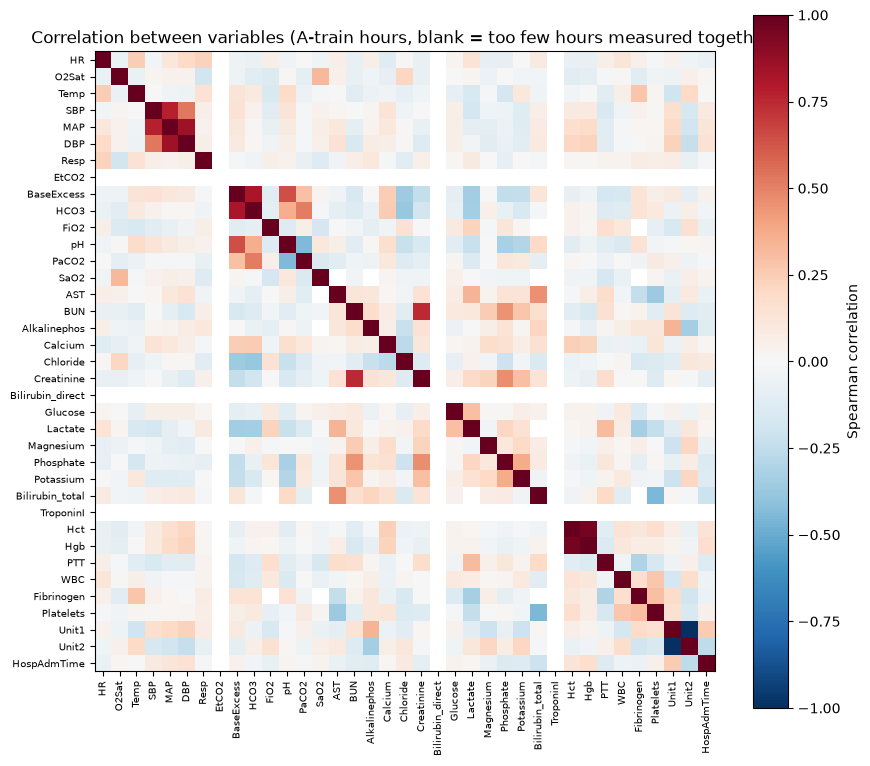

In [11]:
a_train_ids = patients.loc[(patients["hospital"] == "A") & (patients["split"] == "train"), "patient_id"]
a_train = data[data["patient_id"].isin(a_train_ids)]
sample = a_train[VARS].sample(n=min(200_000, len(a_train)), random_state=SEED)
corr = sample.corr(method="spearman", min_periods=500)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), corr.index, fontsize=7)
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Correlation between variables (A-train hours, blank = too few hours measured together)")
fig.savefig(FIG / "eda_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Pairs of strongly correlated variables (|rho| >= 0.7), each pair listed once
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack()
pairs[pairs.abs() >= 0.7].sort_values(key=abs, ascending=False)

Unit1       Unit2        -1.000
Hct         Hgb           0.956
MAP         DBP           0.847
BaseExcess  HCO3          0.820
SBP         MAP           0.779
BUN         Creatinine    0.744
dtype: float64

**Observations.** Six pairs are strongly correlated (|rho| >= 0.7) in the A-train hours:
- **Unit1 and Unit2** (rho = −1): exact duplicates, the two columns encode the same ICU type
  (Unit2 = 1 − Unit1). One of them can be dropped.
- **Hct and Hgb** (0.96): both measure red blood cells.
- **MAP with DBP** (0.85) **and SBP** (0.78): the mean arterial pressure is a weighted average of the
  systolic and diastolic pressures.
- **BaseExcess and HCO3** (0.82): both describe the acid–base balance (bicarbonate).
- **BUN and Creatinine** (0.74): both are kidney-function markers.

These pairs carry almost the same information twice. The L2 penalty of the logistic regression
keeps the model stable, but the coefficients of a correlated pair must not be interpreted one by one.

## 6. Differences between hospitals A and B (Kolmogorov–Smirnov tests)

For each variable we compare its distribution in A and in B with a two-sample KS test.
The KS test assumes independent observations, but hours of the same patient are not independent,
so each patient contributes **one value per variable: the median of his measurements**.

- `ks_D` (between 0 and 1) is the largest gap between the two cumulative distributions:
  it measures **how different** A and B are. We rank variables by `ks_D`.
- With about 20 000 patients per hospital, even tiny differences give a very small p-value,
  so the p-value alone says little here.

In [13]:
KS_VARS = VARS + ["Age", "Gender"]
patient_medians = data.groupby(["hospital", "patient_id"])[KS_VARS].median()

rows = []
for v in KS_VARS:
    a = patient_medians.loc["A", v].dropna()
    b = patient_medians.loc["B", v].dropna()
    row = {"variable": v, "n_patients_A": len(a), "n_patients_B": len(b)}
    if len(a) >= 2 and len(b) >= 2:            # the test needs values in both hospitals
        test = ks_2samp(a, b)
        row.update(ks_D=test.statistic, p_value=test.pvalue, median_A=a.median(), median_B=b.median())
    rows.append(row)

ks = pd.DataFrame(rows).sort_values("ks_D", ascending=False)
ks

,variable,n_patients_A,n_patients_B,ks_D,p_value,median_A,median_B
27,TroponinI,489,6564,0.669,3.175e-199,3.40,0.075
20,Bilirubin_direct,586,1471,0.464,3.096e-82,1.00,0.200
8,BaseExcess,12652,558,0.359,3.504e-62,0.00,-2.400
36,HospAdmTime,20335,20000,0.320,0.000e+00,-2.77,-8.570
13,SaO2,7963,5125,0.314,2.336e-272,97.00,97.550
4,MAP,20334,19898,0.268,0.000e+00,76.25,84.750
5,DBP,12952,19973,0.251,0.000e+00,58.00,65.000
10,FiO2,11987,5822,0.212,2.204e-155,0.50,0.400
9,HCO3,19801,416,0.202,4.191e-15,24.00,23.475
14,AST,5893,8464,0.186,7.431e-106,42.00,28.000


**Observations.**
- Largest differences between A and B (ks_D): TroponinI (0.67), Bilirubin_direct (0.46),
  BaseExcess (0.36), HospAdmTime (0.32), SaO2 (0.31), MAP (0.27), DBP (0.25), FiO2 (0.21), HCO3 (0.20).
- Some lab values differ in level by a large factor: median TroponinI 3.40 in A vs 0.075 in B
  (about 45 times lower), Bilirubin_direct 1.0 vs 0.2. Such gaps are unlikely to come from the
  patients alone: different lab assays or units, or a different choice of who gets tested
  (TroponinI is measured in only 489 patients in A vs 6 564 in B). These variables are not
  comparable across hospitals.
- Some variables are measured in very few patients of one hospital (BaseExcess: 558 patients in B,
  HCO3: 416, Chloride: 1 617, vs 12 600–19 800 in A). Their test compares small tested subgroups and
  mixes "who is tested" with "which values".
- Patients reach the ICU later after hospital admission in B: median HospAdmTime −8.6 h vs −2.8 h in A.
- Blood pressure is higher in B: median MAP 84.8 vs 76.3 mmHg, DBP 65 vs 58, SBP 124.5 vs 117.5.
- Small differences (ks_D < 0.07): HR, O2Sat, Glucose, BUN, Magnesium, Platelets, Phosphate, Lactate;
  Age (0.09; median 64.7 years in A vs 62.0 in B) and Gender (0.05) differ little. Unit1/Unit2
  (0.004): where it is known, the mix of ICU types is the same.
- EtCO2 cannot be tested: it is never measured in A.
- As expected with ~20 000 patients, almost every p-value is tiny; ks_D is what we compare.
- Together with section 3: the shift between hospitals lies mostly in **what is measured and how**
  (lab panels, assays, blood pressure, admission timing) rather than in the core vital signs.

## 7. Summary for the report

- **Data.** 40 336 patients (A: 20 336, B: 20 000), 1.55 million patient-hours. Same length of stay in
  both hospitals (median 38–39 h); the records were shaped by the organisers (no stay under 8 h,
  very few over 60 h, cap at 336 h).
- **Imbalance.** Only 2.2 % (A) and 1.4 % (B) of hours are positive; always answering "no sepsis"
  gives ~98 % accuracy, so the **AUPRC** is the main metric. Sepsis is 1.5 times more frequent in A
  (**label-prevalence shift**): a model trained on A will tend to overestimate the risk in B, so
  calibration must be checked on B.
- **Missing values.** Vital signs are measured most hours, lab values rarely, and missingness is
  informative, hence last-observed values + "never measured" indicators (notebook 02). The hospitals
  measure different things (blood gases in A, EtCO2 only in B, DBP more often in B):
  **missingness shift**.
- **Outliers.** Physically impossible extremes (Temp 20.9 / 50 °C, Resp 100 /min, blood pressure
  300 mmHg) and capped limits: values are kept, and clipped at A-train percentiles inside the Pipeline
  of the logistic baseline.
- **Redundancy.** Unit1/Unit2 are duplicates; Hct/Hgb, MAP/SBP/DBP, BaseExcess/HCO3 and BUN/Creatinine
  are strongly correlated: L2 regularisation, and no one-by-one reading of their coefficients.
- **Shift.** The largest A/B differences are in lab values and measurement practice (TroponinI,
  Bilirubin_direct, BaseExcess, HospAdmTime, blood pressure); HR, O2Sat and Glucose barely differ.
  We therefore expect a performance drop from A to B, measured in the evaluation notebook
  (internal vs external test).